# 04 — Feature engineering : construire les variables du modèle

À partir du fichier propre (`data/processed/logements_paca.parquet`), on construit :

1. **la cible** : le logarithme du prix de vente ;
2. **le découpage temporel** : entraînement sur 2021-2024, test sur 2025 ;
3. **les variables du bien** : surface, pièces, terrain, dépendances ;
4. **les variables temporelles** : date de la vente ;
5. **les variables géographiques** : distance à la mer, distance aux grandes villes ;
6. **le prix des ventes voisines**, en évitant la fuite de données.

Le résultat est sauvegardé dans `data/processed/features.parquet`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.neighbors import BallTree

racine = Path.cwd()
while not (racine / "data" / "raw").exists() and racine != racine.parent:
    racine = racine.parent

chemin = racine / "data" / "processed" / "logements_paca.parquet"
if not chemin.exists():
    raise FileNotFoundError(f"Fichier introuvable : {chemin}\n→ Lance d'abord le notebook 02_nettoyage jusqu'au bout.")

logements = pd.read_parquet(chemin).sort_values("date_mutation")
logements["code_departement"] = logements["code_departement"].astype(str).str.zfill(2)

dossier_fig = racine / "figures"
dossier_fig.mkdir(exist_ok=True)

RAYON_TERRE_KM = 6371.0
print(logements.shape)

(434089, 14)


## 1. La cible et le découpage temporel

**La cible** est le logarithme du prix (`log_prix`). L'analyse exploratoire a montré une distribution très étirée vers la droite et une relation surface-prix linéaire en échelle log. Avec le log, une erreur de 10 % pèse autant pour un studio à 100 000 € que pour une villa à 1 M€.

**Le découpage est temporel** : on entraîne sur les ventes de 2021 à 2024 et on teste sur 2025. Cela simule l'usage réel, où l'on estime des ventes futures avec ce qu'on sait du passé. Un découpage aléatoire mélangerait des ventes de 2025 dans l'entraînement et donnerait des performances trop optimistes.

In [2]:
logements["log_prix"] = np.log(logements["valeur_fonciere"])
logements["log_prix_m2"] = np.log(logements["prix_m2"])

logements["jeu"] = np.where(logements["date_mutation"] < "2025-01-01", "train", "test")
logements.groupby(["jeu", "type_local"]).size().unstack()

type_local,Appartement,Maison
jeu,,
test,55318,27017
train,235086,116668


## 2. Variables du bien

In [3]:
logements["est_maison"] = (logements["type_local"] == "Maison").astype(int)
logements["log_surface"] = np.log(logements["surface_reelle_bati"])
logements["surface_par_piece"] = logements["surface_reelle_bati"] / logements["nombre_pieces_principales"]
logements["log_terrain"] = np.log1p(logements["surface_terrain"])  # log(1 + x) : gère les terrains à 0

logements[["log_surface", "nombre_pieces_principales", "surface_par_piece", "log_terrain", "nb_dependances"]].describe()

,log_surface,nombre_pieces_principales,surface_par_piece,log_terrain,nb_dependances
count,434089.000000,434089.000000,434089.000000,434089.000000,434089.000000
mean,4.126432,3.054125,23.751524,1.952344,0.825796
std,0.549520,1.421531,7.528534,3.092870,0.860963
min,2.197225,1.000000,0.965517,0.000000,0.000000
25%,3.761200,2.000000,19.250000,0.000000,0.000000
50%,4.174387,3.000000,22.333333,0.000000,1.000000
75%,4.488636,4.000000,26.666667,5.267858,1.000000
max,7.402452,68.000000,385.000000,15.459224,68.000000


## 3. Variables temporelles

- `mois_depuis_2021` capte la **tendance du marché** (hausse, baisse, reprise) ;
- `mois` capte une éventuelle **saisonnalité** (plus de ventes l'été, par exemple).

In [4]:
date = logements["date_mutation"]
logements["mois_depuis_2021"] = (date.dt.year - 2021) * 12 + date.dt.month - 1
logements["mois"] = date.dt.month
logements[["mois_depuis_2021", "mois"]].describe()

,mois_depuis_2021,mois
count,434089.000000,434089.000000
mean,27.754493,6.591526
std,17.570306,3.372445
min,0.000000,1.000000
25%,13.000000,4.000000
50%,26.000000,7.000000
75%,43.000000,9.000000
max,59.000000,12.000000


## 4. Distance aux grandes villes

On calcule la distance « à vol d'oiseau » entre chaque logement et les principales villes de la région, avec la **formule de haversine**, qui tient compte de la courbure de la Terre.

In [5]:
def distance_km(lat1, lon1, lat2, lon2):
    """Distance à vol d'oiseau (formule de haversine), en km."""
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * RAYON_TERRE_KM * np.arcsin(np.sqrt(a))


VILLES = {
    "marseille": (43.2965, 5.3698),
    "nice": (43.7102, 7.2620),
    "toulon": (43.1242, 5.9280),
    "aix": (43.5297, 5.4474),
    "avignon": (43.9493, 4.8055),
}

for ville, (lat, lon) in VILLES.items():
    logements[f"dist_{ville}_km"] = distance_km(logements["latitude"], logements["longitude"], lat, lon)

colonnes_villes = [f"dist_{v}_km" for v in VILLES]
logements["dist_grande_ville_km"] = logements[colonnes_villes].min(axis=1)
logements[colonnes_villes + ["dist_grande_ville_km"]].describe().round(1)

,dist_marseille_km,dist_nice_km,dist_toulon_km,dist_aix_km,dist_avignon_km,dist_grande_ville_km
count,434089.0,434089.0,434089.0,434089.0,434089.0,434089.0
mean,84.3,102.4,80.8,80.2,123.9,24.5
std,57.3,64.8,44.9,48.3,57.7,27.3
min,0.1,0.1,0.0,0.0,0.1,0.0
25%,34.3,28.7,47.0,32.4,84.9,4.6
50%,81.5,122.2,78.3,68.7,128.1,17.8
75%,138.0,157.0,120.0,126.7,179.0,33.2
max,221.3,235.2,223.7,195.3,228.9,168.5


## 5. Distance à la mer

La carte a montré que la proximité de la mer est un facteur majeur. On trace le littoral de PACA avec une **ligne simplifiée** d'environ 70 points, de la Camargue à Menton, densifiée tous les 200 m. Pour chaque logement, on cherche ensuite le point du littoral le plus proche.

Pour éviter de calculer 434 000 × 2 000 distances, on utilise un **BallTree** (scikit-learn), une structure qui trouve très vite le plus proche voisin.

*Limite : le tracé est simplifié (précision de l'ordre du kilomètre). C'est suffisant pour distinguer « bord de mer », « à 10 km » et « arrière-pays ».*

In [6]:
# Points du littoral (latitude, longitude), d'ouest en est
LITTORAL = [
    (43.452, 4.428), (43.360, 4.580), (43.355, 4.730), (43.375, 4.830), (43.400, 4.950),
    (43.330, 5.040), (43.330, 5.110), (43.330, 5.150), (43.340, 5.250), (43.360, 5.310),
    (43.295, 5.365), (43.260, 5.375), (43.245, 5.370), (43.215, 5.350), (43.210, 5.420),
    (43.210, 5.445), (43.205, 5.500), (43.213, 5.535), (43.200, 5.560), (43.175, 5.607),
    (43.175, 5.680), (43.135, 5.750), (43.117, 5.800), (43.075, 5.800), (43.050, 5.860),
    (43.090, 5.890), (43.115, 5.930), (43.105, 5.940), (43.095, 5.960), (43.085, 6.020),
    (43.085, 6.070), (43.070, 6.130), (43.030, 6.130), (43.090, 6.160), (43.110, 6.170),
    (43.120, 6.200), (43.125, 6.240), (43.100, 6.320), (43.137, 6.370), (43.150, 6.430),
    (43.160, 6.480), (43.170, 6.530), (43.165, 6.620), (43.200, 6.680), (43.230, 6.660),
    (43.270, 6.640), (43.270, 6.585), (43.310, 6.640), (43.340, 6.720), (43.390, 6.730),
    (43.420, 6.740), (43.420, 6.770), (43.430, 6.860), (43.510, 6.940), (43.520, 6.940),
    (43.550, 7.010), (43.565, 7.070), (43.565, 7.110), (43.545, 7.130), (43.585, 7.130),
    (43.640, 7.140), (43.655, 7.160), (43.665, 7.190), (43.660, 7.210), (43.690, 7.250),
    (43.695, 7.285), (43.700, 7.310), (43.685, 7.330), (43.705, 7.335), (43.715, 7.360),
    (43.720, 7.400), (43.735, 7.425), (43.755, 7.470), (43.775, 7.500), (43.785, 7.530),
]


def densifier(points, pas_km=0.2):
    """Ajoute des points intermédiaires tous les `pas_km` km le long de la ligne."""
    resultat = []
    for (lat1, lon1), (lat2, lon2) in zip(points[:-1], points[1:]):
        n = max(1, int(np.ceil(distance_km(lat1, lon1, lat2, lon2) / pas_km)))
        t = np.linspace(0, 1, n, endpoint=False)
        resultat.append(np.column_stack([lat1 + t * (lat2 - lat1), lon1 + t * (lon2 - lon1)]))
    resultat.append(np.array([points[-1]]))
    return np.vstack(resultat)


littoral = densifier(LITTORAL)
arbre_littoral = BallTree(np.radians(littoral), metric="haversine")
distance, _ = arbre_littoral.query(np.radians(logements[["latitude", "longitude"]].to_numpy()), k=1)
logements["dist_mer_km"] = distance[:, 0] * RAYON_TERRE_KM

print(f"{len(littoral)} points de littoral")
# Vérification sur quelques communes connues
(logements[logements["nom_commune"].isin(["Saint-Tropez", "Cassis", "Nice", "Aix-en-Provence", "Avignon", "Digne-les-Bains", "Gap"])]
 .groupby("nom_commune")["dist_mer_km"].median().round(1).sort_values())

1837 points de littoral


nom_commune
Saint-Tropez         0.4
Cassis               0.6
Nice                 1.4
Aix-en-Provence     21.5
Avignon             61.2
Digne-les-Bains     85.1
Gap                132.5
Name: dist_mer_km, dtype: float64

Les valeurs doivent être cohérentes : quasiment 0 km pour Saint-Tropez, Cassis ou Nice, une vingtaine de kilomètres pour Aix, et bien plus pour Avignon, Digne ou Gap.

On visualise le tracé sur la carte des ventes pour vérifier qu'il suit bien la côte :

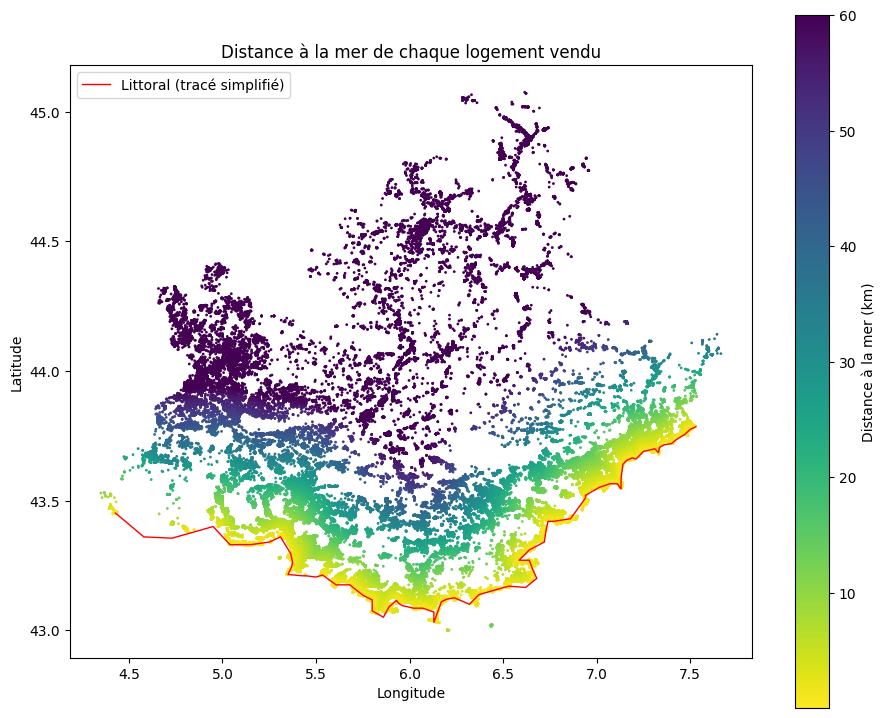

In [7]:
fig, ax = plt.subplots(figsize=(11, 9))
points = ax.scatter(logements["longitude"], logements["latitude"], c=logements["dist_mer_km"],
                    s=1, cmap="viridis_r", vmax=60)
ax.plot(littoral[:, 1], littoral[:, 0], color="red", linewidth=1, label="Littoral (tracé simplifié)")
fig.colorbar(points, ax=ax, label="Distance à la mer (km)")
ax.set_aspect(1 / np.cos(np.radians(43.8)))
ax.set(title="Distance à la mer de chaque logement vendu", xlabel="Longitude", ylabel="Latitude")
ax.legend(loc="upper left")
fig.savefig(dossier_fig / "distance_mer.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Le prix des ventes voisines (et le piège de la fuite de données)

C'est la variable la plus puissante : **le prix au m² médian des 20 ventes les plus proches** (du même type de bien). Elle résume en un chiffre « combien vaut le quartier ».

Mais elle est piégeuse. On parle de **fuite de données** (*data leakage*) quand une variable contient, directement ou indirectement, la réponse qu'on cherche à prédire. Ici, deux erreurs sont possibles :

1. **Inclure la vente elle-même parmi ses voisines.** Son propre prix entrerait dans la variable, et le modèle apprendrait à « tricher ». Sur les données d'entraînement, on cherche donc 21 voisines et **on retire la vente elle-même** (méthode *leave-one-out*).
2. **Utiliser les ventes de 2025 pour calculer la variable.** On utiliserait alors des informations du futur. Les voisines sont donc **toujours cherchées parmi les ventes d'entraînement** (2021-2024), y compris pour les ventes de test.

On calcule aussi la **distance à la 20ᵉ voisine** : elle mesure la densité de ventes autour du logement (petite en ville, grande à la campagne) et indique au modèle si la variable de voisinage est fiable.

In [8]:
K = 20


def prix_voisins(df, k=K):
    """Prix au m² médian (en log) des k ventes d'entraînement les plus proches, sans fuite de données."""
    resultat = pd.DataFrame(index=df.index, columns=["voisins_log_prix_m2", "voisins_distance_km"], dtype=float)

    for type_local in ["Appartement", "Maison"]:
        sous = df[df["type_local"] == type_local]
        train = sous[sous["jeu"] == "train"]
        test = sous[sous["jeu"] == "test"]

        arbre = BallTree(np.radians(train[["latitude", "longitude"]].to_numpy()), metric="haversine")
        prix_train = train["log_prix_m2"].to_numpy()

        # Entraînement : k+1 voisins, puis on retire la vente elle-même
        dist, idx = arbre.query(np.radians(train[["latitude", "longitude"]].to_numpy()), k=k + 1)
        soi_meme = idx == np.arange(len(train))[:, None]
        # Si plusieurs ventes ont exactement les mêmes coordonnées, la vente elle-même
        # peut ne pas figurer parmi les k+1 : on retire alors la plus éloignée
        soi_meme[~soi_meme.any(axis=1), -1] = True
        idx = idx[~soi_meme].reshape(len(train), k)
        dist = dist[~soi_meme].reshape(len(train), k)
        resultat.loc[train.index, "voisins_log_prix_m2"] = np.median(prix_train[idx], axis=1)
        resultat.loc[train.index, "voisins_distance_km"] = dist[:, -1] * RAYON_TERRE_KM

        # Test : k voisins, cherchés uniquement parmi les ventes d'entraînement
        if len(test):
            dist, idx = arbre.query(np.radians(test[["latitude", "longitude"]].to_numpy()), k=k)
            resultat.loc[test.index, "voisins_log_prix_m2"] = np.median(prix_train[idx], axis=1)
            resultat.loc[test.index, "voisins_distance_km"] = dist[:, -1] * RAYON_TERRE_KM

    return resultat


voisins = prix_voisins(logements)
logements[["voisins_log_prix_m2", "voisins_distance_km"]] = voisins
logements[["voisins_log_prix_m2", "voisins_distance_km"]].describe()

,voisins_log_prix_m2,voisins_distance_km
count,434089.000000,434089.000000
mean,8.188364,0.296761
std,0.406109,0.642992
min,6.675896,0.000000
25%,7.923659,0.045106
50%,8.221965,0.113494
75%,8.474298,0.309199
max,9.651331,20.742119


**Vérification** : le prix des voisines permet-il de deviner le prix au m² d'une vente de 2025 ? Si les points s'alignent autour de la diagonale, la variable est informative.

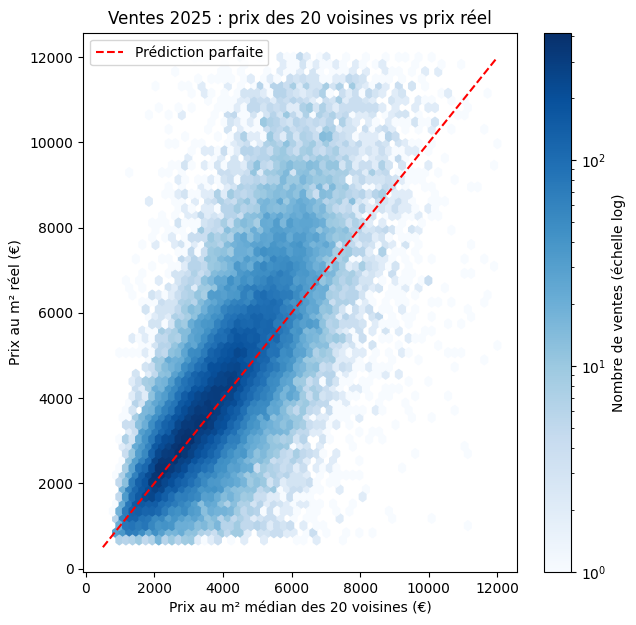

Erreur médiane en prenant simplement le prix des voisines : 16.9%


In [9]:
test = logements[logements["jeu"] == "test"]

fig, ax = plt.subplots(figsize=(7, 7))
hb = ax.hexbin(np.exp(test["voisins_log_prix_m2"]), test["prix_m2"], gridsize=60, bins="log", cmap="Blues",
               extent=(500, 12000, 500, 12000))
ax.plot([500, 12000], [500, 12000], color="red", linestyle="--", label="Prédiction parfaite")
fig.colorbar(hb, ax=ax, label="Nombre de ventes (échelle log)")
ax.set(title="Ventes 2025 : prix des 20 voisines vs prix réel",
       xlabel="Prix au m² médian des 20 voisines (€)", ylabel="Prix au m² réel (€)")
ax.legend()
fig.savefig(dossier_fig / "prix_voisins_vs_reel.png", dpi=150, bbox_inches="tight")
plt.show()

erreur = np.abs(np.exp(test["voisins_log_prix_m2"]) / test["prix_m2"] - 1)
print(f"Erreur médiane en prenant simplement le prix des voisines : {erreur.median():.1%}")

Ce dernier chiffre est déjà une première **baseline** : le modèle de machine learning devra faire mieux que « le prix au m² du quartier ».

## 7. Quelles variables sont liées au prix ?

On mesure la **corrélation** de chaque variable avec le log du prix au m², sur les données d'entraînement uniquement. C'est un premier aperçu. Le modèle captera aussi des relations non linéaires et des interactions qu'une corrélation ne montre pas.

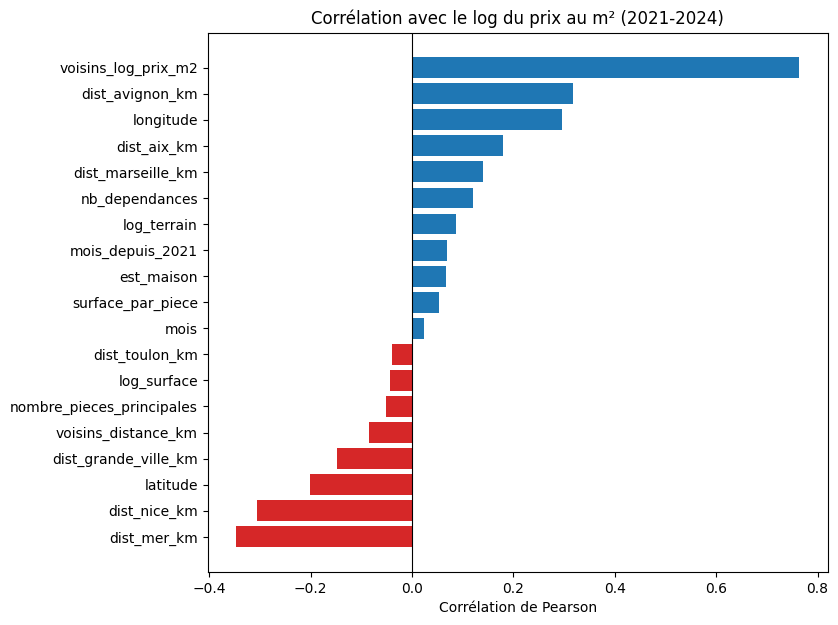

dist_mer_km                 -0.348
dist_nice_km                -0.306
latitude                    -0.201
dist_grande_ville_km        -0.148
voisins_distance_km         -0.086
nombre_pieces_principales   -0.050
log_surface                 -0.044
dist_toulon_km              -0.040
mois                         0.024
surface_par_piece            0.053
est_maison                   0.066
mois_depuis_2021             0.069
log_terrain                  0.088
nb_dependances               0.120
dist_marseille_km            0.141
dist_aix_km                  0.179
longitude                    0.296
dist_avignon_km              0.318
voisins_log_prix_m2          0.764
dtype: float64

In [10]:
FEATURES = [
    # Le bien
    "est_maison", "log_surface", "nombre_pieces_principales", "surface_par_piece", "log_terrain", "nb_dependances",
    # Le temps
    "mois_depuis_2021", "mois",
    # La localisation
    "latitude", "longitude", "dist_mer_km", "dist_grande_ville_km", *colonnes_villes,
    # Le voisinage
    "voisins_log_prix_m2", "voisins_distance_km",
]

train = logements[logements["jeu"] == "train"]
correlations = train[FEATURES].corrwith(train["log_prix_m2"]).sort_values()

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(correlations.index, correlations.values,
        color=["tab:red" if c < 0 else "tab:blue" for c in correlations.values])
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Corrélation avec le log du prix au m² (2021-2024)", xlabel="Corrélation de Pearson")
fig.savefig(dossier_fig / "correlations_features.png", dpi=150, bbox_inches="tight")
plt.show()
correlations.round(3)

## 8. Sauvegarde

In [11]:
colonnes_a_garder = FEATURES + [
    "code_departement", "type_local", "nom_commune", "date_mutation", "jeu",
    "valeur_fonciere", "surface_reelle_bati", "prix_m2", "log_prix", "log_prix_m2",
]
assert logements[FEATURES].notna().all().all(), "Des valeurs manquantes dans les features"

logements[colonnes_a_garder].to_parquet(racine / "data" / "processed" / "features.parquet")
print(f"Sauvegardé : {len(logements):,} ventes, {len(FEATURES)} features")

Sauvegardé : 434,089 ventes, 19 features
